# Beach safety — feature engineering
Turns the raw **panel** (beach × month) and **person** tables into modelling-ready tables for:

| Model | Unit | Target | Levers that act here |
|---|---|---|---|
| Frequency | beach-month | `n_people` (NB, offset `log_visitors`) | campaigns |
| Severity | person | `sev` (logistic, beach random intercept) | lifeguard coverage, drones |

Design rules, taken from the EDA:
1. **Only information known before the incident.** Reporting dates and raw response times are excluded.
2. **Levers stay in cost units.** Raw `lg_hrs`, `drone_hrs` and `campaign_idx` are kept next to their engineered versions, so a funding scenario can change hours and rebuild every feature.
3. **One feature per redundant group.**
4. **The severity model gets a small budget.** About 220 events supports roughly 15–20 parameters.

All feature logic lives in `beach_features.py` (written by the next cell). The allocation notebook can import it and call `panel_features()` / `person_features()` on counterfactual inputs, so the transforms are identical.

In [1]:
%%writefile beach_features.py
"""Feature construction for the beach-safety frequency and severity models.

Pure functions of the raw tables plus two fitted objects (coverage model, scaler),
so they can be re-applied to counterfactual funding scenarios."""
import json
import numpy as np
import pandas as pd

START = pd.Timestamp("2016-09-01")
SWELL_BIG = 2.1          # m; severe share roughly doubles above this (EDA)
SWELL_CENTRE = 1.5       # m; fixed centring constant for the swell interaction
LG_CAP = 850.0           # lifeguard hrs/month where on-duty coverage saturates (EDA)
LG_MAX = 5000.0          # scenario ceiling for lifeguard hrs/month (observed max ≈ 3,500)
WINTER = {5, 6, 7, 8}

# ---------------------------------------------------------------- column decisions
DROPPED = {   # raw column -> reason it is not used as a feature
    "postcode":        "identifier, not a covariate",
    "swell_avg_m":     "r=0.97 with swell_max_m; swell_max carries the severity signal",
    "air_temp_hi":     "r=0.79 with water_temp and collinear with season; keep water_temp",
    "turbidity":       "r=0.66 with rain_mm and partly caused by it; keep rain_mm",
    "n_bins":          "r=0.92 with visitors and no variation within a beach",
    "icecream_visits": "crowd/summer proxy (r=0.74 with visitors, 0.73 with temperature)",
    "patrolled":       "equivalent to lg_hrs > 0 (lg_hrs is exactly 0 when unpatrolled); see lg_on",
    "n_lifeguards":    "deterministic given on_duty (0 iff off duty)",
    "drone_present":   "noisy person-level flag (Y for only 19% of incidents at drone beaches); use drone_hrs",
    "inc_hour":        "replaced by night flag; night is always off duty so on_duty carries it",
    "month_key":       "duplicate of month",
    "sex":             "encoded as male",
    "swim_level":      "encoded as swim_beginner / swim_intermediate (ref = experienced)",
    "local_ind":       "encoded as non_local",
    "age":             "encoded as age_0_17 / age_55p (ref = 18-54; U-shaped risk)",
    "surfer":          "encoded as surfer_yes / surfer_unknown (candidate only: no signal)",
    "inc_cause":       "candidate only: no severity signal; encoded as cause_* dummies",
    "marine_health":   "candidate only: weak signal; encoded as marine_health_low",
    "shore_len_m":     "encoded as log_shore_len and used in log_visitor_density",
    "visitors":        "used as offset log_visitors",
}
EXCLUDED = {  # post-outcome, target or identifier: never a feature
    "dte_reported":    "post-outcome: reporting lag exists only for severe cases",
    "dte_occurred":    "date; information already in month",
    "response_min":    "post-outcome and contaminated by reporting lag (1440 x lag added)",
    "report_lag_days": "post-outcome (perfect proxy for severity)",
    "inc_type":        "target (encoded as sev)",
    "n_mild":          "outcome", "n_closecall": "outcome",
}

# ---------------------------------------------------------------- feature sets
FREQ_CORE = [  # + C(mo) and beach random intercept; offset log_visitors
    "t_years", "swell_max_m", "water_temp", "rain_mm", "wind_days", "tourist_ratio", "surfer_prop",
    "n_rips", "rocky", "fishing", "rockpool", "log_shore_len",
    "coverage_hat", "drone_on", "campaign_on",
]
SEV_CORE = [   # + beach random intercept (incident as cluster for SEs)
    "age_0_17", "age_55p", "male", "swim_beginner", "swim_intermediate", "non_local", "alone",
    "on_duty", "drone_on", "swell_max_m", "winter", "rocky", "n_rips",
]
SEV_INTERACTIONS = ["drone_x_offduty", "onduty_x_swell", "campaign_x_nonlocal"]
CANDIDATES = [  # test, expect to drop
    "big_swell", "log_visitor_density", "drone_dose", "campaign_idx", "log1p_lg_hrs", "lg_hrs_cap",
    "surfer_yes", "surfer_unknown", "cause_physical", "cause_animal", "cause_unknown",
    "multi_person", "night", "marine_health_low", "flags",
]
INFRA_CANDIDATES = ["equip_rating", "first_aid_cap", "pa_system"]   # 'rescue infrastructure' lever; mostly between-beach
LEVERS_RAW = ["lg_hrs", "drone_hrs", "campaign_idx"]
IDS = ["beach_nm", "month", "date", "mo", "fy", "split"]


def _calendar(df):
    df = df.copy()
    df["date"] = pd.to_datetime(df["month"], format="%m/%Y")
    df["mo"] = df.date.dt.month
    df["fy"] = df.date.dt.year + (df.mo >= 9)            # Sep-Aug season, labelled by end year
    df["t_years"] = (df.date - START).dt.days / 365.25
    return df


def coverage_hat(lg_hrs, mo, coverage_model):
    """Expected share of incidents with a lifeguard on duty, given lifeguard hours and month."""
    X = pd.DataFrame({"lg_hrs": np.clip(np.asarray(lg_hrs, float), 0, LG_MAX), "mo": np.asarray(mo, int)})
    p = np.zeros(len(X))
    on = X.lg_hrs > 0
    if on.any():
        p[on.values] = np.asarray(coverage_model.predict(X[on]))
    return p


def panel_features(P, coverage_model, test_from_fy=2025):
    """Beach-month features. P: raw panel (or a counterfactual copy with levers changed)."""
    P = _calendar(P)
    F = P[["beach_nm", "month", "date", "mo", "fy", "t_years"]].copy()
    F["split"] = np.where(F.fy >= test_from_fy, "test", "train")
    for c in ["n_incidents", "n_people", "n_severe"]:
        if c in P:
            F[c] = P[c]
    # exposure
    F["visitors"] = P.visitors
    F["log_visitors"] = np.log(P.visitors)
    # season and environment
    F["winter"] = P.mo.isin(WINTER).astype(int)
    F["swell_max_m"] = P.swell_max_m
    F["big_swell"] = (P.swell_max_m > SWELL_BIG).astype(int)
    F["water_temp"] = P.water_temp
    F["rain_mm"] = P.rain_mm
    F["wind_days"] = P.wind_days
    # visitor mix and crowding
    F["tourist_ratio"] = P.tourist_ratio
    F["surfer_prop"] = P.surfer_prop
    F["log_visitor_density"] = np.log(P.visitors / P.shore_len_m)
    # static beach attributes
    for c in ["n_rips", "rocky", "fishing", "rockpool"]:
        F[c] = P[c]
    F["log_shore_len"] = np.log(P.shore_len_m)
    # levers: raw (cost units) + engineered
    for c in LEVERS_RAW:
        F[c] = P[c]
    F["lg_on"] = (P.lg_hrs > 0).astype(int)
    F["log1p_lg_hrs"] = np.log1p(P.lg_hrs)
    F["lg_hrs_cap"] = np.minimum(P.lg_hrs, LG_CAP) / 100
    F["coverage_hat"] = coverage_hat(P.lg_hrs, P.mo, coverage_model)
    F["drone_on"] = (P.drone_hrs > 0).astype(int)
    F["drone_dose"] = P.drone_hrs / 100
    F["campaign_on"] = (P.campaign_idx > 0).astype(int)
    # infrastructure / other candidates
    for c in INFRA_CANDIDATES + ["flags"]:
        F[c] = P[c]
    F["marine_health_low"] = (P.marine_health == "L").astype(int)
    return F


def person_features(Q, F_panel):
    """Person-level features joined to the beach-month features (single source of truth for covariates)."""
    Q = Q.copy()
    G = pd.DataFrame({"incident_id": Q.incident_id, "person_no": Q.person_no,
                      "beach_nm": Q.beach_nm, "month": Q.month})
    if "inc_type" in Q:
        G["sev"] = (Q.inc_type == "Severe").astype(int)
    G["age_0_17"] = (Q.age <= 17).astype(int)
    G["age_55p"] = (Q.age >= 55).astype(int)
    G["male"] = (Q.sex == "M").astype(int)
    G["swim_beginner"] = (Q.swim_level == "beginner").astype(int)
    G["swim_intermediate"] = (Q.swim_level == "intermediate").astype(int)
    G["non_local"] = (Q.local_ind == "not_local").astype(int)
    G["alone"] = Q.alone.astype(int)
    G["on_duty"] = Q.on_duty.astype(int)
    G["night"] = (~Q.inc_hour.between(7, 19)).astype(int)
    G["surfer_yes"] = (Q.surfer.astype(str).isin(["1.0", "1"])).astype(int)
    G["surfer_unknown"] = (Q.surfer.astype(str) == "unknown").astype(int)
    G["cause_physical"] = (Q.inc_cause == "Physical_injury").astype(int)
    G["cause_animal"] = (Q.inc_cause == "Animal_Encounter").astype(int)
    G["cause_unknown"] = (Q.inc_cause == "unknown").astype(int)
    G["multi_person"] = (Q.incident_size > 1).astype(int)
    G = G.merge(F_panel, on=["beach_nm", "month"], how="left", validate="many_to_one")
    # interactions
    G["drone_x_offduty"] = G.drone_on * (1 - G.on_duty)
    G["onduty_x_swell"] = G.on_duty * (G.swell_max_m - SWELL_CENTRE)
    G["campaign_x_nonlocal"] = G.campaign_on * G.non_local
    return G


# ---------------------------------------------------------------- scaling (fit on train only)
def fit_scaler(df, cols):
    tr = df[df.split == "train"]
    return {c: {"mean": float(tr[c].mean()), "sd": float(tr[c].std())} for c in cols}


def apply_scaler(df, scaler):
    df = df.copy()
    for c, s in scaler.items():
        df[c + "_z"] = (df[c] - s["mean"]) / s["sd"]
    return df


def save_scaler(scaler, path):
    with open(path, "w") as f:
        json.dump(scaler, f, indent=2)


def load_scaler(path):
    with open(path) as f:
        return json.load(f)


Overwriting beach_features.py


In [2]:
import importlib, json, os, pickle
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
import beach_features as bf; importlib.reload(bf)
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 80)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'font.size': 9})
BLUE, ORANGE, GREY, RED = '#2a6f97', '#e07a2f', '#9aa5b1', '#c0392b'

DATA = '/root/.claude/uploads/f3881ce1-0286-5e83-962a-5d99d517c18a/'   # adjust to your local folder
OUT = 'features/'; os.makedirs(OUT, exist_ok=True)
P_raw = pd.read_csv(DATA + '962bdbbe-panel.csv')
Q_raw = pd.read_csv(DATA + '27dea4d8-person.csv')
print(P_raw.shape, Q_raw.shape)

(9600, 34) (33941, 48)


## 1. Account for every raw column
Every raw column must end up as a feature, an encoded feature, a documented drop, or an exclusion. If the data changes, the assertion below fails loudly instead of silently ignoring a new column.

In [3]:
used_directly = {'beach_nm','month','visitors','swell_max_m','water_temp','rain_mm','wind_days','tourist_ratio','surfer_prop',
                 'n_rips','rocky','fishing','rockpool','lg_hrs','drone_hrs','campaign_idx','equip_rating',
                 'first_aid_cap','pa_system','flags','on_duty','alone','incident_size','incident_id','person_no',
                 'n_incidents','n_people','n_severe'}
raw_cols = set(P_raw.columns) | set(Q_raw.columns)
unaccounted = raw_cols - used_directly - set(bf.DROPPED) - set(bf.EXCLUDED)
assert not unaccounted, f'unaccounted raw columns: {unaccounted}'
audit = pd.DataFrame([(c, 'used' if c in used_directly else 'dropped/encoded' if c in bf.DROPPED else 'EXCLUDED',
                       bf.DROPPED.get(c, bf.EXCLUDED.get(c, ''))) for c in sorted(raw_cols)],
                     columns=['raw_column', 'status', 'reason'])
audit.sort_values('status')

,raw_column,status,reason
16,inc_type,EXCLUDED,target (encoded as sev)
28,n_mild,EXCLUDED,outcome
38,response_min,EXCLUDED,post-outcome and contaminated by reporting lag...
25,n_closecall,EXCLUDED,outcome
7,dte_occurred,EXCLUDED,date; information already in month
8,dte_reported,EXCLUDED,post-outcome: reporting lag exists only for se...
36,postcode,dropped/encoded,"identifier, not a covariate"
27,n_lifeguards,dropped/encoded,deterministic given on_duty (0 iff off duty)
24,n_bins,dropped/encoded,r=0.92 with visitors and no variation within a...
23,month_key,dropped/encoded,duplicate of month


## 2. Lifeguard coverage model (first stage)
The EDA showed that lifeguard hours affect severity **through** whether a lifeguard is on duty when the incident happens, and that coverage saturates. This small model turns hours into expected coverage:

$$\Pr(\text{on\_duty}=1 \mid \text{lg\_hrs}, \text{month}) = \operatorname{logit}^{-1}\!\big(\beta \log(1+\text{lg\_hrs}) + \gamma_{\text{month}}\big), \quad \beta > 0$$

Because $\beta > 0$, coverage can only rise with hours, and each extra hour adds less (it saturates). Allocation needs both properties; a flexible spline was tried and rejected because it bent downward at high hours. It is fitted on **training seasons only** and only on beach-months with `lg_hrs > 0`; with zero hours, coverage is exactly 0.

How it is used:
- The **severity model** uses observed `on_duty`.
- The **allocation** step uses `coverage_hat` to translate extra funded hours into a higher on-duty probability, and from there into lower severity.
- The **frequency model** can use `coverage_hat` directly as its lifeguard term.

In [4]:
Qc = Q_raw.copy()
Qc['date'] = pd.to_datetime(Qc.month, format='%m/%Y'); Qc['mo'] = Qc.date.dt.month
Qc['fy'] = Qc.date.dt.year + (Qc.mo >= 9)
fit_rows = Qc[(Qc.lg_hrs > 0) & (Qc.fy < 2025)]
# Logistic in log-hours: monotone by construction and saturating.
# A 4-df B-spline fitted slightly better in-sample but bent DOWN above ~3,000 h (fewer coverage with more
# lifeguards: unusable for allocation) and gave the same test log-loss (0.3749 vs 0.3751).
cov_model = smf.logit('on_duty ~ np.log1p(lg_hrs) + C(mo)', fit_rows).fit(disp=0)
assert cov_model.params['np.log1p(lg_hrs)'] > 0
print(f'fitted on {len(fit_rows):,} incidents; pseudo-R2 = {cov_model.prsquared:.3f}')

# out-of-sample check on the test seasons
te = Qc[(Qc.lg_hrs > 0) & (Qc.fy >= 2025)].copy()
te['p'] = cov_model.predict(te)
ll = -np.mean(te.on_duty*np.log(te.p) + (1-te.on_duty)*np.log(1-te.p))
print(f'test seasons: mean predicted {te.p.mean():.3f} vs observed {te.on_duty.mean():.3f}; log-loss {ll:.4f}')
print(f'slope on log(1+hrs) = {cov_model.params["np.log1p(lg_hrs)"]:.2f}')
# monotonicity check over the full range a scenario could reach, every month
hrs = np.linspace(1, bf.LG_MAX, 500)
for m in range(1, 13):
    p = bf.coverage_hat(hrs, np.full_like(hrs, m), cov_model)
    assert np.all(np.diff(p) >= 0), f'coverage decreases in month {m}'
print('coverage_hat is non-decreasing in hours for every month')

fitted on 22,974 incidents; pseudo-R2 = 0.267
test seasons: mean predicted 0.779 vs observed 0.778; log-loss 0.3751
slope on log(1+hrs) = 1.76
coverage_hat is non-decreasing in hours for every month


,obs,pred,hrs,n
lg_bin,,,,
"(-1, 0]",0.000,0.000,0.00,4122
"(0, 100]",0.329,0.296,85.50,514
"(100, 200]",0.366,0.419,111.40,295
"(200, 350]",0.355,0.308,311.45,1764
"(350, 500]",0.430,0.445,417.80,4864
"(500, 700]",0.689,0.698,597.15,3960
"(700, 850]",0.779,0.800,762.70,2194
"(850, 1200]",0.769,0.836,920.10,973
"(1200, 1800]",0.941,0.893,1680.70,1735


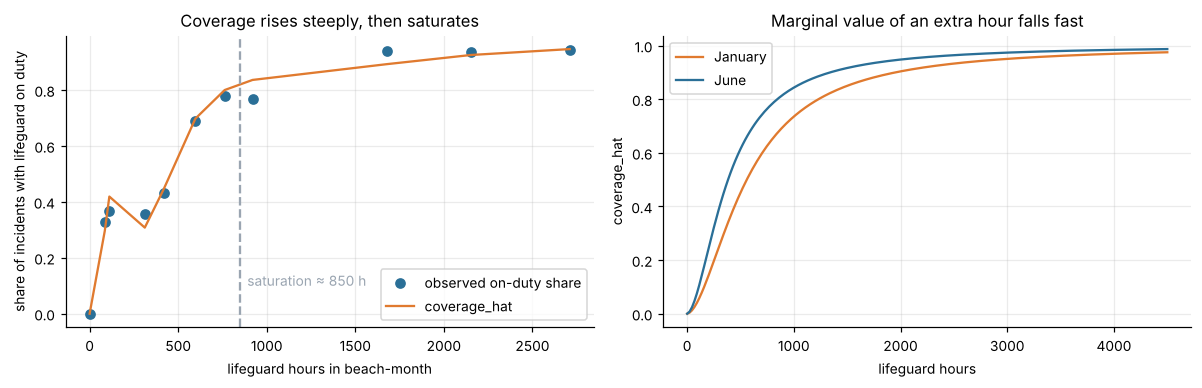

In [5]:
Qc['p'] = bf.coverage_hat(Qc.lg_hrs, Qc.mo, cov_model)
Qc['lg_bin'] = pd.cut(Qc.lg_hrs, [-1, 0, 100, 200, 350, 500, 700, 850, 1200, 1800, 2400, 3500])
g = Qc.groupby('lg_bin', observed=True).agg(obs=('on_duty', 'mean'), pred=('p', 'mean'), hrs=('lg_hrs', 'median'), n=('on_duty', 'size'))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(g.hrs, g.obs, 'o', color=BLUE, label='observed on-duty share')
ax[0].plot(g.hrs, g.pred, '-', color=ORANGE, label='coverage_hat')
ax[0].axvline(bf.LG_CAP, ls='--', color=GREY); ax[0].text(bf.LG_CAP + 40, .1, 'saturation ≈ 850 h', color=GREY)
ax[0].set(xlabel='lifeguard hours in beach-month', ylabel='share of incidents with lifeguard on duty',
          title='Coverage rises steeply, then saturates'); ax[0].legend()
grid = pd.DataFrame({'lg_hrs': np.tile(np.linspace(1, 4500, 200), 2), 'mo': np.repeat([1, 6], 200)})
grid['p'] = cov_model.predict(grid)
for m, c, lab in [(1, ORANGE, 'January'), (6, BLUE, 'June')]:
    d = grid[grid.mo == m]; ax[1].plot(d.lg_hrs, d.p, color=c, label=lab)
ax[1].set(xlabel='lifeguard hours', ylabel='coverage_hat', title='Marginal value of an extra hour falls fast'); ax[1].legend()
plt.tight_layout()
g.round(3)

## 3. Build the feature tables

In [6]:
F = bf.panel_features(P_raw, cov_model)
G = bf.person_features(Q_raw, F)

# scale continuous features with TRAIN statistics only (binary features left as 0/1)
cont = ['t_years', 'swell_max_m', 'water_temp', 'rain_mm', 'wind_days', 'tourist_ratio', 'surfer_prop', 'n_rips',
        'log_shore_len', 'log_visitor_density', 'coverage_hat', 'drone_dose', 'campaign_idx',
        'log1p_lg_hrs', 'lg_hrs_cap', 'equip_rating', 'first_aid_cap']
scaler = bf.fit_scaler(F, cont)
F = bf.apply_scaler(F, scaler)
G = bf.apply_scaler(G, scaler)
print('panel features :', F.shape, '| split:', F.split.value_counts().to_dict())
print('person features:', G.shape, '| split:', G.split.value_counts().to_dict())
F.head(3)

panel features : (9600, 58) | split: {'train': 7680, 'test': 1920}
person features: (33941, 79) | split: {'train': 26139, 'test': 7802}


,beach_nm,month,date,mo,fy,t_years,split,n_incidents,n_people,n_severe,visitors,log_visitors,winter,swell_max_m,big_swell,water_temp,rain_mm,wind_days,tourist_ratio,surfer_prop,log_visitor_density,n_rips,rocky,fishing,rockpool,log_shore_len,lg_hrs,drone_hrs,campaign_idx,lg_on,log1p_lg_hrs,lg_hrs_cap,coverage_hat,drone_on,drone_dose,campaign_on,equip_rating,first_aid_cap,pa_system,flags,marine_health_low,t_years_z,swell_max_m_z,water_temp_z,rain_mm_z,wind_days_z,tourist_ratio_z,surfer_prop_z,n_rips_z,log_shore_len_z,log_visitor_density_z,coverage_hat_z,drone_dose_z,campaign_idx_z,log1p_lg_hrs_z,lg_hrs_cap_z,equip_rating_z,first_aid_cap_z
0,Bondi Beach,09/2016,2016-09-01,9,2017,0.000000,train,10,12,0,67164,11.114893,0,1.94,0,16.9,150.4,14,0.667,0.160,4.812274,3.1,0,0,0,6.302619,539.7,0.0,0.0,1,6.292865,5.397,0.915624,0,0.0,0,78,42.5,1,1,0,-1.713210,0.270157,-1.186623,0.233283,2.853808,1.489557,-0.584889,0.84073,-1.025763,1.606963,1.598020,-0.373555,-0.509445,0.796420,0.687480,0.728013,-0.166373
1,Bondi Beach,10/2016,2016-10-01,10,2017,0.082136,train,54,55,2,135166,11.814259,0,0.93,0,16.9,15.4,12,0.609,0.108,5.511640,3.1,0,0,0,6.302619,2789.1,0.0,0.0,1,7.933833,8.500,0.944960,0,0.0,0,78,56.7,1,1,0,-1.677640,-1.064422,-1.186623,-1.048597,2.141908,1.156125,-0.984011,0.84073,-1.025763,2.007378,1.679567,-0.373555,-0.509445,1.299757,1.624429,0.728013,0.734082
2,Bondi Beach,11/2016,2016-11-01,11,2017,0.167009,train,6,6,0,159258,11.978281,0,1.34,0,20.2,54.7,12,0.589,0.139,5.675662,3.1,0,0,0,6.302619,2716.5,0.0,0.0,1,7.907468,8.500,0.952076,0,0.0,0,78,50.4,1,1,0,-1.640885,-0.522662,0.094186,-0.675427,2.141908,1.041149,-0.746073,0.84073,-1.025763,2.101286,1.699349,-0.373555,-0.509445,1.291670,1.624429,0.728013,0.334584


## 4. Sanity checks

In [7]:
checks = {
    'panel rows = 80 x 120': len(F) == 80 * 120,
    'person rows preserved': len(G) == len(Q_raw),
    'every person row matched a beach-month': G.date.notna().all(),
    'no missing values (panel)': not F.isna().any().any(),
    'no missing values (person)': not G.isna().any().any(),
    'no post-outcome column in either table': not (set(bf.EXCLUDED) - {'n_mild', 'n_closecall'}) & (set(F) | set(G)),
    'joined covariates match person file': np.allclose(G.swell_max_m, Q_raw.swell_max_m) and np.allclose(G.lg_hrs, Q_raw.lg_hrs),
    'severe count = 220': int(G.sev.sum()) == 220,
    'coverage_hat = 0 when unpatrolled': (F.loc[F.lg_hrs == 0, 'coverage_hat'] == 0).all(),
    'scaled train means ≈ 0': np.allclose(F.loc[F.split == 'train', [c + '_z' for c in cont]].mean(), 0, atol=1e-9),
}
assert all(checks.values()), {k: v for k, v in checks.items() if not v}
pd.Series(checks)

panel rows = 80 x 120                     True
person rows preserved                     True
every person row matched a beach-month    True
no missing values (panel)                 True
no missing values (person)                True
no post-outcome column in either table    True
joined covariates match person file       True
severe count = 220                        True
coverage_hat = 0 when unpatrolled         True
scaled train means ≈ 0                    True
dtype: bool

## 5. Collinearity in the core sets
Variance inflation factors (VIF) on the features each model will use. Rough rule: below 5 is fine, and 5–10 needs a justification.

In [8]:
def vif(df, cols):
    X = df[cols].astype(float).assign(const=1.0)
    return pd.Series({c: variance_inflation_factor(X.values, i) for i, c in enumerate(cols)}).round(2).sort_values(ascending=False)

freq_vif = vif(F, bf.FREQ_CORE + ['winter'])            # winter stands in for month dummies here
sev_vif = vif(G, bf.SEV_CORE)
pd.concat({'frequency core': freq_vif, 'severity core': sev_vif}, axis=1)

,frequency core,severity core
water_temp,1.97,NaN
winter,1.78,1.16
rocky,1.72,1.13
log_shore_len,1.69,NaN
n_rips,1.64,1.12
fishing,1.59,NaN
coverage_hat,1.46,NaN
swell_max_m,1.33,1.18
campaign_on,1.31,NaN
drone_on,1.28,1.04


Every core feature has a VIF below 2, so neither model has a collinearity problem after the drops.
- `water_temp`, `winter` and `coverage_hat` are the most related (all seasonal), but still low. The frequency model uses month effects rather than `winter`.
- Among candidates, `drone_dose` (4.7 against `drone_on`) is the only notable one. Use one or the other, not both.
- The static beach attributes (`n_rips`, `rocky`, `fishing`, `rockpool`, `log_shore_len`) are only identified across beaches. With a beach **random** intercept they stay estimable; with beach **fixed** effects they must be dropped.

In [9]:
print('candidate features vs core: VIF if added one at a time to the severity core')
print(pd.Series({c: vif(G, bf.SEV_CORE + [c])[c] for c in bf.CANDIDATES + bf.SEV_INTERACTIONS if c in G}).round(2).sort_values(ascending=False))

candidate features vs core: VIF if added one at a time to the severity core


drone_dose             4.67
big_swell              2.62
log1p_lg_hrs           2.46
onduty_x_swell         2.44
lg_hrs_cap             2.09
drone_x_offduty        2.00
log_visitor_density    1.48
cause_unknown          1.28
campaign_x_nonlocal    1.24
night                  1.18
campaign_idx           1.13
surfer_yes             1.11
flags                  1.10
marine_health_low      1.06
cause_physical         1.05
multi_person           1.03
cause_animal           1.00
surfer_unknown         1.00
dtype: float64


## 6. Feature dictionary and parameter budget

In [10]:
DESC = {
  'log_visitors': ('offset', 'freq', 'log monthly visitors (exposure)'),
  't_years': ('control', 'freq', 'years since Sep-2016; trend (forecastable, unlike year FE)'),
  'winter': ('control', 'sev (freq uses C(mo))', 'May–Aug; severe share 2–3x higher'),
  'swell_max_m': ('control', 'freq, sev', 'max swell height (m)'),
  'big_swell': ('candidate', 'sev', 'swell_max_m > 2.1 m threshold'),
  'water_temp': ('control', 'freq', 'water temperature (chosen over air temp)'),
  'rain_mm': ('control', 'freq', 'rainfall (chosen over turbidity)'),
  'wind_days': ('control', 'freq', 'windy days in month; small frequency effect (+1%/day), none on severity'),
  'tourist_ratio': ('control', 'freq', 'share of visitors who are tourists'),
  'surfer_prop': ('control', 'freq', 'share of visitors surfing'),
  'log_visitor_density': ('candidate', 'freq', 'log(visitors per metre of shoreline)'),
  'n_rips': ('control', 'freq, sev', 'number of rips (static)'),
  'rocky': ('control', 'freq, sev', 'rocky beach (static)'),
  'fishing': ('control', 'freq', 'fishing beach (static)'),
  'rockpool': ('control', 'freq', 'rock pool present (static)'),
  'log_shore_len': ('control', 'freq', 'log shoreline length (static)'),
  'lg_hrs': ('lever (raw)', 'scenario input', 'lifeguard hours/month (cost units)'),
  'coverage_hat': ('lever', 'freq; allocation link to sev', 'expected on-duty share from first-stage model'),
  'log1p_lg_hrs': ('candidate', 'freq', 'alternative lifeguard transform'),
  'lg_hrs_cap': ('candidate', 'freq', 'min(lg_hrs, 850)/100'),
  'lg_on': ('diagnostic', '-', '= patrolled'),
  'drone_hrs': ('lever (raw)', 'scenario input', 'drone hours/month (cost units)'),
  'drone_on': ('lever', 'freq, sev', 'drone_hrs > 0; robust severity effect in EDA'),
  'drone_dose': ('candidate', 'sev', 'drone_hrs/100'),
  'campaign_idx': ('lever (raw) / candidate', 'scenario input', 'campaign intensity (0 = none)'),
  'campaign_on': ('lever', 'freq', 'campaign active; strong frequency effect in EDA'),
  'equip_rating': ('infra candidate', 'freq, sev', 'equipment rating; ~90% between-beach variation'),
  'first_aid_cap': ('infra candidate', 'freq, sev', 'first-aid capacity; ~70% between-beach'),
  'pa_system': ('infra candidate', 'sev', 'PA system present'),
  'flags': ('candidate', 'sev', 'flags present'),
  'marine_health_low': ('candidate', 'sev', 'marine health = L'),
  'sev': ('target', 'sev', 'person severity = Severe'),
  'age_0_17': ('control', 'sev', 'age ≤ 17 (ref 18–54)'), 'age_55p': ('control', 'sev', 'age ≥ 55'),
  'male': ('control', 'sev', 'sex = M'),
  'swim_beginner': ('control', 'sev', 'ref = experienced'), 'swim_intermediate': ('control', 'sev', 'ref = experienced'),
  'non_local': ('control', 'sev', 'not local'), 'alone': ('control', 'sev', 'alone at incident'),
  'on_duty': ('lever (mechanism)', 'sev', 'lifeguard on duty; linked to lg_hrs via coverage_hat'),
  'night': ('candidate', 'sev', 'hour outside 7–19 (always off duty)'),
  'surfer_yes': ('candidate', 'sev', ''), 'surfer_unknown': ('candidate', 'sev', 'missingness as a level'),
  'cause_physical': ('candidate', 'sev', 'ref = swimming'), 'cause_animal': ('candidate', 'sev', ''),
  'cause_unknown': ('candidate', 'sev', ''), 'multi_person': ('candidate', 'sev', 'incident_size > 1'),
  'drone_x_offduty': ('interaction', 'sev', 'do drones fill lifeguard gaps?'),
  'onduty_x_swell': ('interaction', 'sev', 'lifeguards matter more in big surf? (swell centred at 1.5 m)'),
  'campaign_x_nonlocal': ('interaction', 'sev', 'campaigns work on tourists?'),
}
fd = pd.DataFrame([(k, *v) for k, v in DESC.items()], columns=['feature', 'role', 'model', 'description'])
fd['in_core'] = fd.feature.map(lambda f: 'freq+sev' if f in bf.FREQ_CORE and f in bf.SEV_CORE
                               else 'freq' if f in bf.FREQ_CORE else 'sev' if f in bf.SEV_CORE else '')
print('Severity core parameters:', len(bf.SEV_CORE), '+ intercept + beach RE variance',
      f'-> {G.sev.sum()} events / {len(bf.SEV_CORE)+1} ≈ {G.sev.sum()/(len(bf.SEV_CORE)+1):.0f} events per parameter')
print('Adding all 3 interactions ->', len(bf.SEV_CORE) + 3, 'parameters')
print('Frequency core:', len(bf.FREQ_CORE), '+ 11 month effects + beach RE;', int(F.n_people.gt(0).sum()), 'non-zero beach-months')
fd

Severity core parameters: 13 + intercept + beach RE variance -> 220 events / 14 ≈ 16 events per parameter
Adding all 3 interactions -> 16 parameters
Frequency core: 15 + 11 month effects + beach RE; 5900 non-zero beach-months


,feature,role,model,description,in_core
0,log_visitors,offset,freq,log monthly visitors (exposure),
1,t_years,control,freq,"years since Sep-2016; trend (forecastable, unl...",freq
2,winter,control,sev (freq uses C(mo)),May–Aug; severe share 2–3x higher,sev
3,swell_max_m,control,"freq, sev",max swell height (m),freq+sev
4,big_swell,candidate,sev,swell_max_m > 2.1 m threshold,
5,water_temp,control,freq,water temperature (chosen over air temp),freq
6,rain_mm,control,freq,rainfall (chosen over turbidity),freq
7,wind_days,control,freq,windy days in month; small frequency effect (+...,freq
8,tourist_ratio,control,freq,share of visitors who are tourists,freq
9,surfer_prop,control,freq,share of visitors surfing,freq


## 7. Save

In [11]:
F.to_csv(OUT + 'panel_features.csv', index=False)
G.to_csv(OUT + 'person_features.csv', index=False)
fd.to_csv(OUT + 'feature_dictionary.csv', index=False)
audit.to_csv(OUT + 'raw_column_audit.csv', index=False)
bf.save_scaler(scaler, OUT + 'scaler.json')
cov_model.save(OUT + 'coverage_model.pkl', remove_data=True)

# round-trip: reload the saved objects and rebuild -> identical features
from statsmodels.iolib.smpickle import load_pickle
cm2 = load_pickle(OUT + 'coverage_model.pkl')
F2 = bf.apply_scaler(bf.panel_features(P_raw, cm2), bf.load_scaler(OUT + 'scaler.json'))
assert np.allclose(F2.coverage_hat, F.coverage_hat) and np.allclose(F2.coverage_hat_z, F.coverage_hat_z)
print(sorted(os.listdir(OUT)))

['coverage_model.pkl', 'feature_dictionary.csv', 'panel_features.csv', 'person_features.csv', 'raw_column_audit.csv', 'scaler.json']


## 8. Using this downstream

**Fitting.**
- Frequency: `n_people ~ FREQ_CORE + C(mo) + (1 | beach_nm)`, negative binomial, `offset = log_visitors`.
- Severity: `sev ~ SEV_CORE + (1 | beach_nm)`.
- Use the `_z` versions of the continuous features. Train on `split == 'train'` (seasons up to 2023–24) and evaluate on `test` (2024–25 and 2025–26).

**Funding scenarios.**
```python
import beach_features as bf
P_scn = P_raw.copy()
P_scn.loc[mask, 'lg_hrs'] += extra_hours      # or drone_hrs / campaign_idx
F_scn = bf.apply_scaler(bf.panel_features(P_scn, cov_model), scaler)
G_scn = bf.apply_scaler(bf.person_features(Q_raw, F_scn), scaler)
# for severity, replace observed on_duty with a draw / expectation from coverage_hat under the new hours
```
Rebuilding through the same functions guarantees the scenario features are transformed exactly like the training data.